
# W06 — Z-Dönüşümüne Giriş  
**Signals & Systems — Yozgat Bozok University**  
*Instructor: Assist. Prof. Ahmet Sertol KÖKSAL*

---

Bu defter; **motivasyon → tanım → ROC → kutup–sıfır → örnekler** sırasıyla ilerler.
Formüller TeX formatında verilmiştir; çizimler için **matplotlib** kullanılmıştır.


## 1) Neden Z-Dönüşümü?

Önceki dersimizde, zaman alanında konvolüsyon (evrişim) hesaplarının zahmetli olduğunu gördük. Z‑dönüşümü ile:

$\displaystyle y[n] = x[n] * h[n] \quad \Longleftrightarrow \quad Y(z) = X(z) \cdot H(z)$

Bu sayede **toplamalar yerine çarpma/bölme** ile çalışırız. Fark denklemleri de cebirsel forma dönüşür.


## 2) Z‑Dönüşümünün Tanımı ve Temel Fikir

Bir ayrık zamanlı $\displaystyle x[n] $ sinyali için **iki‑taraflı Z‑dönüşüm**:

$\displaystyle X(z) = \sum_{n=-\infty}^{\infty} x[n] z^{-n}, \qquad z = re^{j\omega}$

Burada $\displaystyle r$ genlik, $\displaystyle \omega$ ise açısal frekanstır. Z‑dönüşümü, sinyali **zaman alanı**ndan **z‑alanı**na taşır.

- Evrişim → çarpım
- Zaman kayması $\displaystyle n_0$ → $\displaystyle z^{-n_0}$ ile çarpma
- Fark denklemi → cebirsel denklem


## 3) Yakınsaklık Bölgesi (ROC) — Sezgi

Z-dönüşüm tanımındaki seri, yalnızca belirli $\displaystyle z$ değerlerinde yakınsaktır. Bu kümeye **ROC** denir.

Örnek geometrik seri (sağ-taraflı):

$\displaystyle \sum_{n=0}^{\infty} (a z^{-1})^n = \frac{1}{1-a z^{-1}} \quad \text{yakınsaklık: } |z| > |a| $

Sol-taraflı için benzer ifade **farklı ROC** ile mümkündür. **Aynı**  $\displaystyle X(z)$ ifadesi, **farklı ROC** ile **farklı** zaman-alanı dizilerine karşılık gelebilir.


### Örnekler

| Sinyal | Z-Dönüşümü | ROC | Tür |
|:--|:--|:--|:--|
| $a^n u[n]$ | $\dfrac{1}{1-a z^{-1}}$ | $|z| > |a|$ | Sağ-taraflı (nedensel) |
| $-a^n u[-n-1]$ | $\dfrac{1}{1-a z^{-1}}$ | $|z| < |a|$ | Sol-taraflı (anti-nedensel) |

In [37]:

# Yardımcı fonksiyonlar: Z-düzlemi, birim çember, kutup-sıfır çizimi ve ROC gölgeleme
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def plot_unit_circle(ax):
    theta = np.linspace(0, 2*np.pi, 600)
    ax.plot(np.cos(theta), np.sin(theta), linestyle='--')
    ax.axhline(0, linewidth=0.5)
    ax.axvline(0, linewidth=0.5)
    ax.set_aspect('equal', 'box')
    ax.set_xlabel('Re{z}')
    ax.set_ylabel('Im{z}')
    ax.set_title('Z-düzlemi ve |z|=1')

def plot_pz(ax, zeros=None, poles=None, title=None):
    plot_unit_circle(ax)
    zeros = np.array([]) if zeros is None else np.asarray(zeros, dtype=complex)
    poles = np.array([]) if poles is None else np.asarray(poles, dtype=complex)
    if zeros.size:
        ax.scatter(zeros.real, zeros.imag, marker='o', label='Zeros')
    if poles.size:
        ax.scatter(poles.real, poles.imag, marker='x', label='Poles')
    if zeros.size or poles.size:
        ax.legend(loc='best')
    if title:
        ax.set_title(title)

def shade_outer_ROC(ax, r0=0.5, rmax=1.5):
    # |z| > r0 (nedensel tipik) için görsel sezgi
    plot_unit_circle(ax)
    c = Circle((0,0), r0, fill=False, linestyle='-')
    ax.add_patch(c)
    N = 400
    x = np.linspace(-rmax, rmax, N)
    y = np.linspace(-rmax, rmax, N)
    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X**2 + Y**2)
    mask = (R > r0).astype(float)
    ax.contourf(X, Y, mask, levels=1, alpha=0.15)
    ax.set_xlim(-rmax, rmax); ax.set_ylim(-rmax, rmax)
    ax.set_title(f'ROC: |z| > {r0}')

def shade_inner_ROC(ax, r0=0.5, rmax=1.5):
    # |z| < r0 (anti-nedensel tipik)
    plot_unit_circle(ax)
    c = Circle((0,0), r0, fill=False, linestyle='-')
    ax.add_patch(c)
    N = 400
    x = np.linspace(-rmax, rmax, N)
    y = np.linspace(-rmax, rmax, N)
    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X**2 + Y**2)
    mask = (R < r0).astype(float)
    ax.contourf(X, Y, mask, levels=1, alpha=0.15)
    ax.set_xlim(-rmax, rmax); ax.set_ylim(-rmax, rmax)
    ax.set_title(f'ROC: |z| < {r0}')

def shade_annulus_ROC(ax, r1=0.4, r2=0.9, rmax=1.5):
    # r1 < |z| < r2 (iki-taraflı) sezgisi
    plot_unit_circle(ax)
    c1 = Circle((0,0), r1, fill=False, linestyle='-')
    c2 = Circle((0,0), r2, fill=False, linestyle='-')
    ax.add_patch(c1); ax.add_patch(c2)
    N = 400
    x = np.linspace(-rmax, rmax, N)
    y = np.linspace(-rmax, rmax, N)
    X, Y = np.meshgrid(x, y)
    R = np.sqrt(X**2 + Y**2)
    mask = ((R > r1) & (R < r2)).astype(float)
    ax.contourf(X, Y, mask, levels=1, alpha=0.15)
    ax.set_xlim(-rmax, rmax); ax.set_ylim(-rmax, rmax)
    ax.set_title(f'ROC: {r1} < |z| < {r2}')



### Z-düzlemi ve Birim Çember
Aşağıdaki grafik Z-düzlemini ve \(|z|=1\) birim çemberini gösterir.


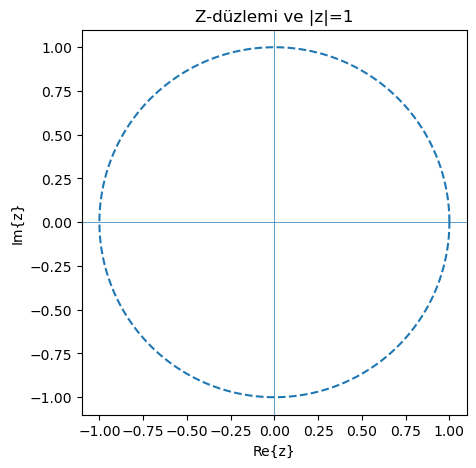

In [38]:

fig, ax = plt.subplots(figsize=(5,5))
plot_unit_circle(ax)
plt.show()



## 4) Kutup–Sıfır (Pole–Zero) Diyagramı

Genel bir biçim:
$\displaystyle H(z) = K \frac{(z - z_1)(z - z_2)\cdots}{(z - p_1)(z - p_2)\cdots} $

- **Kutup:** paydayı sıfırlayan noktalar
- **Sıfır:** payı sıfırlayan noktalar


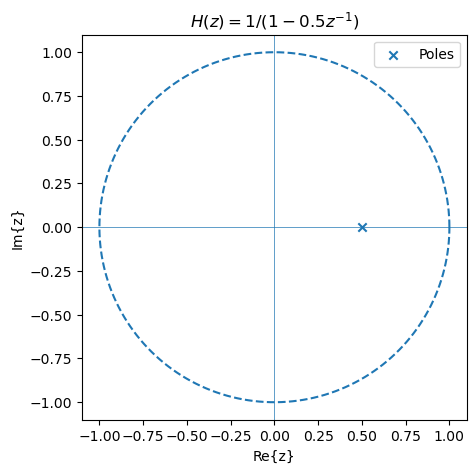

In [39]:

# Örnek: H(z) = 1 / (1 - 0.5 z^{-1})  -> kutup z = 0.5, sıfır yok
poles = np.array([0.5+0j])
zeros = np.array([])

fig, ax = plt.subplots(figsize=(5,5))
plot_pz(ax, zeros=zeros, poles=poles, title='$ H(z) = 1 / (1 - 0.5 z^{-1}) $')
plt.show()



## 5) Nedensellik ve Kararlılık (ROC Üzerinden)

- **Nedensellik (sağ-taraflı \(h[n]\))**: ROC, en dıştaki kutbun **dışında** olur.  
- **Kararlılık (BIBO)**: ROC **birim çemberi** (\(|z|=1\)) içermelidir.



### 5.1 Nedensel Tipik ROC: $|z| > r_0$


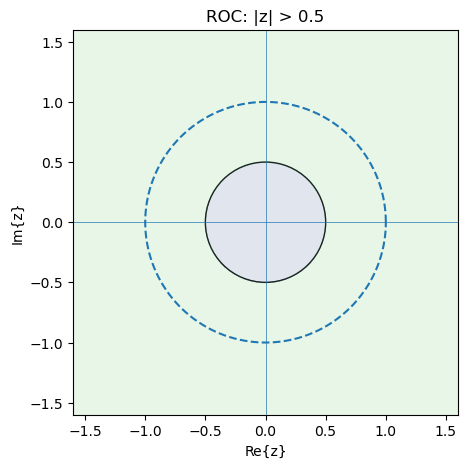

In [40]:

fig, ax = plt.subplots(figsize=(5,5))
shade_outer_ROC(ax, r0=0.5, rmax=1.6)
plt.show()



### 5.2 Anti-nedensel Tipik ROC: $|z| < r_0$


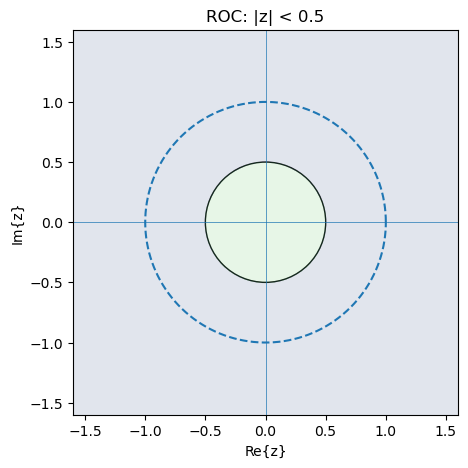

In [41]:

fig, ax = plt.subplots(figsize=(5,5))
shade_inner_ROC(ax, r0=0.5, rmax=1.6)
plt.show()



### 5.3 İki-Taraflı Bir Dizi İçin ROC: $r_1 < |z| < r_2$


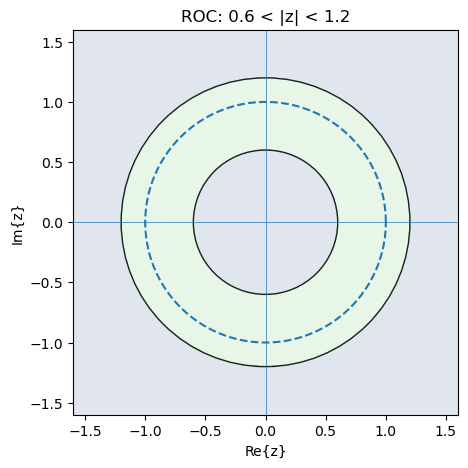

In [42]:

fig, ax = plt.subplots(figsize=(5,5))
shade_annulus_ROC(ax, r1=0.6, r2=1.2, rmax=1.6)
plt.show()



## 6) Fark Denklemi → Z-Dönüşümü → $H(z)$

Örnek fark denklemi:
$\displaystyle y[n] - 0.5\,y[n-1] = x[n] $

Z-dönüşümü:
$\displaystyle Y(z) - 0.5 z^{-1} Y(z) = X(z) \;\Rightarrow\; H(z) = \frac{Y(z)}{X(z)} = \frac{1}{1 - 0.5 z^{-1}}$

Kutup: $z=0.5$. Nedensel/stabil seçim için tipik ROC: $|z| > 0.5$.  
Zaman alanı (sezgi): $h[n] = (0.5)^n u[n]$.


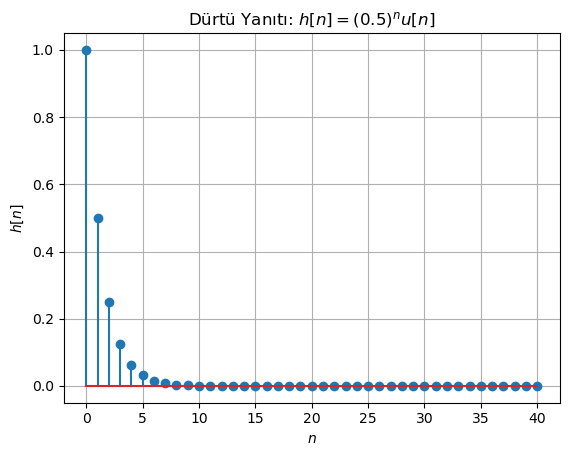

In [43]:

# h[n] = (0.5)^n u[n] örneği (sonlu gösterim için 0..40 arası)
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(0, 41)
h = (0.5)**n

fig = plt.figure()
plt.stem(n, h)
plt.xlabel('$n$')
plt.ylabel('$h[n]$')
plt.title('Dürtü Yanıtı: $h[n] = (0.5)^n u[n]$')
plt.grid(True)
plt.show()



## 7) FIR ve IIR Sistemlerin Z-Alanı Yorumu

| Sistem Türü | Z-Alan Özelliği | \(h[n]\) | Kararlılık |
|:--|:--|:--|:--|
| **FIR** | Payda sabit (kutuplar yok) | Sonlu süreli | Her zaman kararlı |
| **IIR** | Paydada z-terimleri (kutuplar var) | Sonsuz süreli | Kutuplar birim çember içinde olmalı |



## Ek — Temel Z-Dönüşüm Çiftleri (ROC ile)
Aşağıdaki temel fonksiyonlar, **W07'de ters Z-dönüşüm** uygularken doğrudan başvuracağımız çekirdek eşleşmelerdir. Her biri için **ROC** açıkça belirtilmiştir.

| # | $x[n]$ | $X(z)$ | ROC | Not |
|:-:|:--|:--|:--|:--|
| 1 | $\delta[n]$ | $1$ | tüm $z$ | Birim dürtü |
| 2 | $u[n]$ | $\dfrac{1}{1 - z^{-1}}$ | $|z| > 1$ | Sağ-taraflı step |
| 3 | $a^n u[n]$ | $\dfrac{1}{1 - a z^{-1}}$ | $|z| > |a|$ | Nedensel geometrik dizi |
| 4 | $-a^n u[-n-1]$ | $\dfrac{1}{1 - a z^{-1}}$ | $|z| < |a|$ | Anti-nedensel geometrik dizi |
| 5 | $a^{n-n_0} u[n-n_0]$ | $z^{-n_0}\,\dfrac{1}{1 - a z^{-1}}$ | $|z| > |a|$ | Kaydırma: $z^{-n_0}$ çarpanı |
| 6 | $\delta[n]-\delta[n-1]$ | $1 - z^{-1}$ | tüm $z$ | İlk fark operatörü |
| 7 | $a^{|n|}$ | $\dfrac{1 - a^2}{(1 - a z^{-1})(1 - a z)}$ | $|a| < |z| < \dfrac{1}{|a|}$ | İki-taraflı örnek (halka-ROC) |

> **Hatırlatma:** Aynı cebirsel $X(z)$ ifadesi, **farklı ROC**'larla **farklı $x[n]$** dizilerine karşılık gelebilir. Bu nedenle ROC, ters Z-dönüşümde doğru çözümü seçmek için kritik önemdedir.


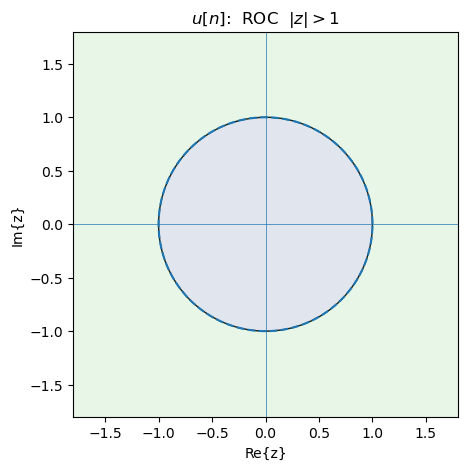

In [44]:

# ROC görselleştirme 1: u[n]  -> X(z) = 1 / (1 - z^{-1}),  ROC: |z| > 1
fig, ax = plt.subplots(figsize=(5,5))
shade_outer_ROC(ax, r0=1.0, rmax=1.8)
ax.set_title('$u[n]$:  ROC  $|z| > 1$')
plt.show()


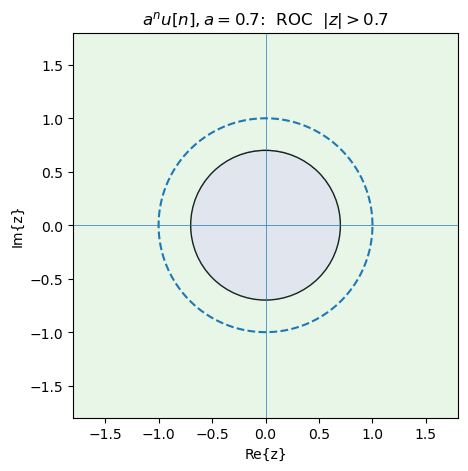

In [45]:

# ROC görselleştirme 2: a^n u[n] (a=0.7) -> X(z) = 1 / (1 - a z^{-1}), ROC: |z| > |a|
fig, ax = plt.subplots(figsize=(5,5))
shade_outer_ROC(ax, r0=0.7, rmax=1.8)
ax.set_title('$a^n u[n], a=0.7$:  ROC  $|z| > 0.7$')
plt.show()


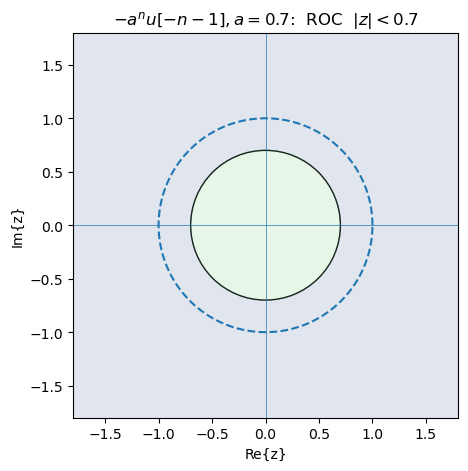

In [46]:

# ROC görselleştirme 3: -a^n u[-n-1] (a=0.7) -> aynı X(z), ROC: |z| < |a|
fig, ax = plt.subplots(figsize=(5,5))
shade_inner_ROC(ax, r0=0.7, rmax=1.8)
ax.set_title('$-a^n u[-n-1], a=0.7$:  ROC  $|z| < 0.7$')
plt.show()


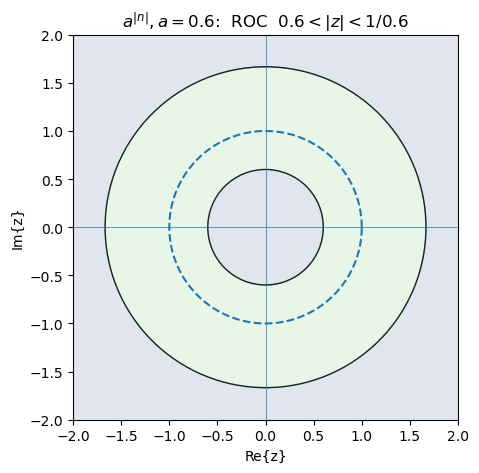

In [47]:

# ROC görselleştirme 4: a^{|n|} (a=0.6) -> halka ROC: a < |z| < 1/a
fig, ax = plt.subplots(figsize=(5,5))
shade_annulus_ROC(ax, r1=0.6, r2=(1/0.6), rmax=2.0)
ax.set_title('$a^{|n|}, a=0.6$:  ROC  $0.6 < |z| < 1/0.6$')
plt.show()


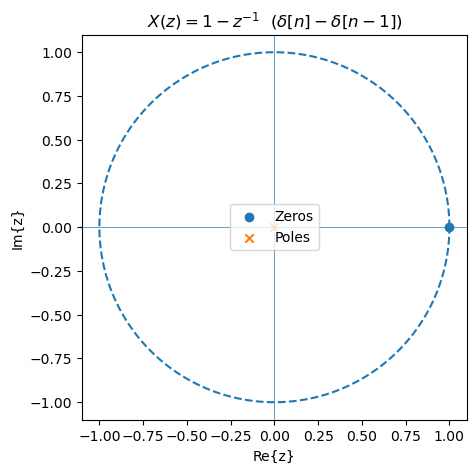

In [48]:

# Kutup–sıfır görselleştirme: X(z) = 1 - z^{-1} = (z-1)/z -> sıfır: z=1, kutup: z=0
fig, ax = plt.subplots(figsize=(5,5))
plot_pz(ax, zeros=[1+0j], poles=[0+0j], title='$X(z) = 1 - z^{-1}$  $( \delta[n] - \delta[n-1] )$')
plt.show()



---

**W06 Özeti**
- Z-dönüşümü evrişimi çarpıma dönüştürür.  
- ROC, yakınsaklık ve sistem özelliklerini tayin eder.  
- Kutuplar birim çembere yaklaştıkça tepkiler yavaş sönümlenir.  
- Fark denklemleri $H(z)$ üzerinden çözümlenebilir.  
- FIR/IIR ayrımı z-düzleminde açıktır.

**W07 Önsöz:** Z-dönüşüm **özellikleri** ve **ters Z-dönüşüm** yöntemleri.
